Model-free collective variables from a spectral matrix D(t, lambda).

SYNTHETIC DATA. Every spectrum, rate constant, band position, noise level, and
concentration in this example is generated by the kipetax models defined below.
Nothing here is measured. The numbers are illustrative, chosen only to be
qualitatively like a real vibrational kinetics experiment, and they are neither
fitted to nor validated against laboratory data. The example demonstrates method
behaviour, not physical parameter values.

These are model-free analyses. They fit no mechanism. Given only the spectral
matrix D(t, lambda), they ask three questions: how many independent processes are
present, how fast do they relax, and is there a single low-dimensional coordinate
that the spectral changes track. Two complementary methods answer different parts
of that question.

Dynamic mode decomposition (DMD, the discrete Koopman approximation) fits the
series as a small set of spatial modes, each evolving as exp(omega_j t). For
bilinear kinetics dc/dt = K c the continuous eigenvalues omega_j are exactly the
eigenvalues of the rate matrix K, that is, the relaxation rates, so a rank-3 DMD
reads the rates of A -> B -> C straight off the spectra with no mechanism
assumed. On the linear system it recovers k1 = 0.9 and k2 = 0.5. The spatial
modes phi_j are the difference spectra, telling what changes at each rate.

A diffusion map answers the geometric question. A single kinetic run traces a
one-dimensional curve through spectral space parametrized by one clock, time. Its
leading nontrivial coordinate psi_1 is a data-driven reaction coordinate,
monotone in the extent of reaction, and it stays one-dimensional even when
spectral interactions inflate the linear (PCA) embedding dimension from three to
five. The intrinsic dimension (one) is not the linear embedding dimension (three
for additive spectra, five once transient adducts break bilinearity). The extra
PCA components are curvature of the same one-dimensional curve, not new processes.

The second half is a stress test. DMD is a linear model of the dynamics, exact
only when the spectra are a sum of exp(omega t) modes. Training DMD on the first
half of a trajectory and predicting forward is essentially exact for the linear
A -> B -> C system but diverges badly for a nonlinear A -> B, 2B -> C system whose
dB/dt carries a quadratic -2 k2 B^2 sink. The rates reported for the nonlinear fit
are local linear surrogates for the dimerization step, not physical constants.
What survives the nonlinearity is geometry: a diffusion-map coordinate still
parametrizes the trajectory that no fixed set of linear modes can predict.

The concentrations for both systems are generated with kipetax ReactionModel
simulations, not analytic formulas and not a hand-rolled integrator. The
collocation solver returns the states at non-uniform collocation points, so each
profile is interpolated onto a uniform time grid before any DMD, because DMD's
omega = log(mu)/dt conversion assumes a uniform sampling interval dt.

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')
import os

## Setup: helper functions and synthetic-data generators

These are lifted verbatim from the example script (`kipetax/examples/Ex_7_model_free_coordinates.py`).

In [2]:
import time

import numpy as np
from scipy.spatial.distance import pdist, squareform

from kipetax import ReactionModel

# ---------------------------------------------------------------------------
# Spectra (copied from Ex_4_spectral_interactions.py). Two adduct bands are
# added so that transient interactions inflate the linear rank from 3 to 5.
# ---------------------------------------------------------------------------
NU = np.linspace(300.0, 1700.0, 100)     # Raman shift, cm^-1
TFINAL = 10.0                            # observation window, arbitrary time units
N_UNIFORM = 60                           # points on the uniform DMD/diffusion grid

K1_LIN, K2_LIN = 0.9, 0.5               # linear A -> B -> C
K1_NON, K2_NON = 0.8, 2.5              # nonlinear A -> B, 2B -> C
A0 = 1.0
G_AB, G_BC = 1.6, 1.6                  # adduct band strengths

def lorentzian(nu, nu0, gamma, amp):
    return amp * gamma ** 2 / ((nu - nu0) ** 2 + gamma ** 2)

def spec_A(nu):
    return lorentzian(nu, 520.0, 15.0, 1.0) + lorentzian(nu, 1000.0, 20.0, 0.6)

def spec_B(nu):
    return lorentzian(nu, 700.0, 18.0, 0.8) + lorentzian(nu, 1350.0, 25.0, 0.7)

def spec_C(nu):
    return lorentzian(nu, 900.0, 20.0, 0.9) + lorentzian(nu, 1600.0, 22.0, 1.0)

def spec_adduct_AB(nu):
    """Band unique to the transient A.B adduct (present only when A and B overlap)."""
    return lorentzian(nu, 1150.0, 20.0, 0.7)

def spec_adduct_BC(nu):
    """Band unique to the transient B.C adduct, added to reach a linear rank of 5."""
    return lorentzian(nu, 1450.0, 20.0, 0.7)

# ---------------------------------------------------------------------------
# Concentration generation via kipetax (no analytic profiles, no hand-rolled RK4)
# ---------------------------------------------------------------------------
def _simulate_to_uniform(model, nfe):
    """Simulate a ReactionModel and interpolate its states onto a uniform grid.

    Parameters
    ----------
    model : ReactionModel
        A fully specified model with ODEs and initial conditions. ``set_time`` is
        applied here; the caller must not have called ``simulate`` yet.
    nfe : int
        Number of finite elements for the collocation discretization.

    Returns
    -------
    t : ndarray, shape (N_UNIFORM,)
        Uniform time grid on [0, TFINAL].
    C : ndarray, shape (N_UNIFORM, 3)
        Columns are the A, B, C concentration profiles on the uniform grid.
    """
    model.set_time(TFINAL)
    model.set_discretization(nfe=nfe, ncp=3)
    model.simulate()                    # raises RuntimeError if collocation fails

    Z = model.results_dict['simulator'].Z
    t = np.linspace(0.0, TFINAL, N_UNIFORM)
    t_coll = Z.index.values             # non-uniform collocation points
    C = np.column_stack([np.interp(t, t_coll, Z[c].values) for c in ('A', 'B', 'C')])
    return t, C

def concentrations_linear():
    """Generate A -> B -> C concentrations with kipetax (k1=0.9, k2=0.5)."""
    r = ReactionModel('linear_ABC')
    k1 = r.parameter('k1', value=K1_LIN, bounds=(0, 10), fixed=True)
    k2 = r.parameter('k2', value=K2_LIN, bounds=(0, 10), fixed=True)
    A = r.component('A', value=A0)
    B = r.component('B', value=0.0)
    C = r.component('C', value=0.0)
    r.add_ode('A', -k1 * A)
    r.add_ode('B', k1 * A - k2 * B)
    r.add_ode('C', k2 * B)
    return _simulate_to_uniform(r, nfe=240)

def concentrations_nonlinear():
    """Generate A -> B, 2B -> C concentrations with kipetax (k1=0.8, k2=2.5).

    The dimerization step gives dB/dt a quadratic -2 k2 B^2 sink, so the
    trajectory is not a sum of exponentials. This is a perfectly ordinary
    ReactionModel; the nonlinearity lives entirely in the ODE expression.
    """
    r = ReactionModel('nonlinear_dimer')
    k1 = r.parameter('k1', value=K1_NON, bounds=(0, 10), fixed=True)
    k2 = r.parameter('k2', value=K2_NON, bounds=(0, 10), fixed=True)
    A = r.component('A', value=A0)
    B = r.component('B', value=0.0)
    C = r.component('C', value=0.0)
    r.add_ode('A', -k1 * A)
    r.add_ode('B', k1 * A - 2 * k2 * B * B)
    r.add_ode('C', k2 * B * B)
    return _simulate_to_uniform(r, nfe=120)

def spectra_additive(C):
    """Bilinear Beer-Lambert spectra D = sum_k c_k s_k, shape (n_time, n_lambda)."""
    cA, cB, cC = C[:, 0], C[:, 1], C[:, 2]
    return (np.outer(cA, spec_A(NU))
            + np.outer(cB, spec_B(NU))
            + np.outer(cC, spec_C(NU)))

def spectra_interacting(C):
    """Additive spectra plus two transient-adduct bands that break bilinearity.

    The A.B band scales as c_A c_B and the B.C band as c_B c_C. Each is a rank-1
    outer product with a new temporal profile, so together they raise the linear
    rank of the spectral matrix from 3 to 5.
    """
    cA, cB, cC = C[:, 0], C[:, 1], C[:, 2]
    D = spectra_additive(C)
    D = D + G_AB * np.outer(cA * cB, spec_adduct_AB(NU))
    D = D + G_BC * np.outer(cB * cC, spec_adduct_BC(NU))
    return D

# ---------------------------------------------------------------------------
# Dynamic mode decomposition (exact DMD)
# ---------------------------------------------------------------------------
def dmd(D, dt, r):
    """Exact DMD of a spectral time series.

    Parameters
    ----------
    D : ndarray, shape (n_time, n_lambda)
        Spectral matrix sampled on a uniform time grid.
    dt : float
        Uniform sampling interval. The continuous eigenvalues use log(mu)/dt,
        which is only valid for uniform sampling.
    r : int
        Rank of the SVD truncation.

    Returns
    -------
    omega : ndarray, shape (r,)
        Continuous-time eigenvalues, sorted by decreasing real part. The
        relaxation rates are -omega.real.
    modes : ndarray, shape (n_lambda, r)
        DMD spatial modes (difference spectra), ordered to match omega.
    """
    X, X2 = D[:-1].T, D[1:].T                       # (n_lambda, n_time-1)
    U, s, Vt = np.linalg.svd(X, full_matrices=False)
    U, s, V = U[:, :r], s[:r], Vt[:r].T
    Atil = U.conj().T @ X2 @ V @ np.diag(1.0 / s)
    mu, W = np.linalg.eig(Atil)
    omega = np.log(mu) / dt
    modes = X2 @ V @ np.diag(1.0 / s) @ W
    order = np.argsort(omega.real)[::-1]
    return omega[order], modes[:, order]

def dmd_train_predict(D, r, m_train, t, dt):
    """Fit DMD on the first ``m_train`` snapshots and predict the full trajectory.

    Parameters
    ----------
    D : ndarray, shape (n_time, n_lambda)
        Spectral matrix on a uniform time grid.
    r : int
        SVD truncation rank.
    m_train : int
        Number of leading snapshots used to fit the linear operator.
    t : ndarray, shape (n_time,)
        Uniform time grid (used to propagate the modes).
    dt : float
        Uniform sampling interval.

    Returns
    -------
    Dpred : ndarray, shape (n_time, n_lambda)
        Reconstruction and forward prediction from the initial spectrum.
    omega : ndarray, shape (r,)
        Continuous-time eigenvalues, sorted by decreasing real part.
    """
    Dtr = D[:m_train]
    X, X2 = Dtr[:-1].T, Dtr[1:].T
    U, s, Vt = np.linalg.svd(X, full_matrices=False)
    U, s, V = U[:, :r], s[:r], Vt[:r].T
    Atil = U.conj().T @ X2 @ V @ np.diag(1.0 / s)
    mu, W = np.linalg.eig(Atil)
    omega = np.log(mu) / dt
    Phi = X2 @ V @ np.diag(1.0 / s) @ W
    b = np.linalg.lstsq(Phi, D[0], rcond=None)[0]
    Dpred = (Phi @ (b[:, None] * np.exp(np.outer(omega, t)))).real.T
    order = np.argsort(omega.real)[::-1]
    return Dpred, omega[order]

# ---------------------------------------------------------------------------
# Diffusion map (geometric reaction coordinate)
# ---------------------------------------------------------------------------
def diffusion_map(D):
    """Leading diffusion-map coordinate of a set of spectra.

    Parameters
    ----------
    D : ndarray, shape (n_time, n_lambda)
        Each row is one spectrum; rows are treated as points in R^n_lambda.

    Returns
    -------
    psi1 : ndarray, shape (n_time,)
        The leading nontrivial diffusion coordinate psi_1 (psi_0 is constant).
    """
    Dm = squareform(pdist(D))
    eps = np.median(Dm[Dm > 0]) ** 2
    Wm = np.exp(-Dm ** 2 / eps)
    P = Wm / Wm.sum(axis=1, keepdims=True)          # row-stochastic Markov matrix
    val, vec = np.linalg.eig(P)
    order = np.argsort(val.real)[::-1]
    return vec.real[:, order[1]]

def linear_rank(D, thr):
    """Count singular values above a noise-floor threshold."""
    sv = np.linalg.svd(D, compute_uv=False)
    return int((sv > thr).sum()), sv

def rmse(a, b):
    return float(np.sqrt(np.mean((a - b) ** 2)))

# ---------------------------------------------------------------------------
# Analyses
# ---------------------------------------------------------------------------
def part1_collective_variables(t_lin, C_lin, results):
    """DMD rates, linear-rank inflation, and the diffusion-map reaction coordinate."""
    dt = float(t_lin[1] - t_lin[0])
    cA = C_lin[:, 0]
    extent = 1.0 - cA / cA[0]                        # monotone extent of A consumption

    D_add = spectra_additive(C_lin)
    D_int = spectra_interacting(C_lin)

    rng = np.random.default_rng(0)
    noise = 2e-3
    D_add_n = D_add + noise * rng.standard_normal(D_add.shape)
    D_int_n = D_int + noise * rng.standard_normal(D_int.shape)

    print("=" * 72)
    print("COLLECTIVE VARIABLES FROM SPECTRA (no species, no mechanism)")
    print("(SYNTHETIC, illustrative data, not experimental measurements.)")
    print("=" * 72)

    # (1) DMD reads the kinetic eigenvalues straight off the additive spectra.
    omega, _ = dmd(D_add_n, dt, r=3)
    rates = np.sort(-omega.real)
    recovered = np.sort(rates[rates > 1e-2])
    print("\n[1] DMD (dynamical CVs) on additive A->B->C spectra, rank 3:")
    print(f"    continuous eigenvalues (rates): {np.round(-omega.real, 3)}")
    print(f"    -> recovered rate constants {np.round(recovered, 3)}  "
          f"(true k2={K2_LIN}, k1={K1_LIN})")
    print("    No mechanism was assumed; the exp(-k t) modes fall out of the data.")

    # (2) Linear rank: interactions inflate the PCA embedding dimension.
    # Noise-edge singular value of an m x n Gaussian block is ~sigma(sqrt m + sqrt n);
    # a threshold at 2.5x that edge keeps genuine modes and rejects the noise floor.
    thr = 2.5 * noise * (np.sqrt(D_add.shape[0]) + np.sqrt(D_add.shape[1]))
    ra, sv_a = linear_rank(D_add_n, thr)
    ri, sv_i = linear_rank(D_int_n, thr)
    print(f"\n[2] Linear rank (PCA embedding dim) at noise floor thr={thr:.3f}:")
    print(f"    additive={ra}   interacting={ri}   (interaction inflates it)")
    print(f"    additive singular values     : {np.round(sv_a[:7], 3)}")
    print(f"    interacting singular values  : {np.round(sv_i[:7], 3)}")

    # (3) Diffusion-map reaction coordinate stays one-dimensional either way.
    psi_a = diffusion_map(D_add)
    psi_i = diffusion_map(D_int)
    corr_a = abs(np.corrcoef(psi_a, extent)[0, 1])
    corr_i = abs(np.corrcoef(psi_i, extent)[0, 1])
    print("\n[3] Diffusion-map coordinate psi_1 (geometric CV) vs extent:")
    print(f"    corr(psi_1, extent):  additive={corr_a:.3f}   interacting={corr_i:.3f}")
    print("    -> one 1-D reaction coordinate, monotone in extent, recovered even")
    print(f"       though interactions push the linear rank to {ri}. Intrinsic")
    print("       dimension (1) is not the linear embedding dimension (3 or 5).")

    results.update(dict(dmd_rates=recovered, rank_add=ra, rank_int=ri,
                        corr_add=corr_a, corr_int=corr_i))

def part2_dmd_stress_test(t_lin, C_lin, t_non, C_non, results):
    """Forward-prediction stress test: linear DMD is exact, nonlinear DMD diverges."""
    dt = float(t_lin[1] - t_lin[0])
    m = N_UNIFORM // 2                               # train on the first half

    lin = spectra_additive(C_lin)
    non = spectra_additive(C_non)

    Dp_lin, om_lin = dmd_train_predict(lin, 3, m, t_lin, dt)
    Dp_non, om_non = dmd_train_predict(non, 3, m, t_non, dt)

    train_lin, pred_lin = rmse(Dp_lin[:m], lin[:m]), rmse(Dp_lin[m:], lin[m:])
    train_non, pred_non = rmse(Dp_non[:m], non[:m]), rmse(Dp_non[m:], non[m:])
    ratio = pred_non / pred_lin

    print("\n" + "=" * 72)
    print("WHERE LINEAR KOOPMAN (DMD) BREAKS")
    print("(SYNTHETIC, illustrative data, not experimental measurements.)")
    print("=" * 72)
    print("\nDMD trained on the first half, predicting the full trajectory:")
    print(f"  linear A->B->C     train RMSE {train_lin:.1e}   PREDICT RMSE {pred_lin:.1e}")
    print(f"  nonlinear 2B->C    train RMSE {train_non:.1e}   PREDICT RMSE {pred_non:.1e}")
    print(f"  -> nonlinear prediction error is ~{ratio:.0e}x the linear one.")
    print(f"\n  DMD rates, linear    : {np.round(np.sort(-om_lin.real), 3)}  "
          f"(true 0, {K2_LIN}, {K1_LIN})")
    print(f"  DMD rates, nonlinear : {np.round(np.sort(-om_non.real), 3)}  "
          f"({K1_NON} is k1; the rest are spurious linear surrogates for 2B->C)")

    # Geometry survives where the linear-dynamics model fails.
    psi = diffusion_map(non)
    arc = np.concatenate([[0.0],
                          np.cumsum(np.linalg.norm(np.diff(non, axis=0), axis=1))])
    arc /= arc[-1]
    corr_arc = abs(np.corrcoef(psi, arc)[0, 1])
    print(f"\n  Nonlinear reaction coordinate: corr(diffusion psi_1, arc length) "
          f"= {corr_arc:.3f}")
    print("  -> geometry survives: a 1-D nonlinear coordinate still parametrizes")
    print("     the trajectory that no fixed set of linear modes can predict.")

    results.update(dict(train_lin=train_lin, pred_lin=pred_lin,
                        train_non=train_non, pred_non=pred_non, ratio=ratio,
                        rates_non=np.sort(-om_non.real), corr_arc=corr_arc))
    return lin, non, Dp_lin, Dp_non, m, psi, arc

def make_figure(t, om_dmd, sv_a, sv_i, thr, extent, psi_a, psi_i,
                lin, non, Dp_non, m, psi_non, arc):
    """Optional summary figure. Skipped if matplotlib is unavailable."""
    try:
        import matplotlib
        import matplotlib.pyplot as plt
    except ImportError:
        print("\n(matplotlib not installed, skipping figure)")
        return

    ipeak = int(np.argmin(np.abs(NU - 1600.0)))
    fig, ax = plt.subplots(2, 3, figsize=(16, 9))

    ax[0, 0].plot(t, np.exp(-K1_LIN * t), 'C0', lw=2, label=f'true exp(-k1 t), k1={K1_LIN}')
    ax[0, 0].plot(t, np.exp(-K2_LIN * t), 'C1', lw=2, label=f'true exp(-k2 t), k2={K2_LIN}')
    for j, om in enumerate(om_dmd):
        rate = -om.real
        if rate > 1e-2:
            ax[0, 0].plot(t, np.exp(-rate * t), 'k--', lw=1.2,
                          label='DMD mode' if j == 1 else None)
    ax[0, 0].set(title='DMD modes recover the kinetic eigenvalues',
                 xlabel='time', ylabel='mode amplitude')
    ax[0, 0].legend(fontsize=8)

    n = np.arange(1, 8)
    ax[0, 1].semilogy(n, sv_a[:7], 'o-', label='additive')
    ax[0, 1].semilogy(n, sv_i[:7], 's-', label='interacting')
    ax[0, 1].axhline(thr, color='k', ls=':', lw=1, label='noise floor')
    ax[0, 1].set(title='Linear (PCA) rank: 3 additive -> 5 interacting',
                 xlabel='component', ylabel='singular value')
    ax[0, 1].legend(fontsize=8)

    ax[0, 2].plot(extent, psi_a, 'o', ms=4, label='additive')
    ax[0, 2].plot(extent, psi_i, 's', ms=4, label='interacting')
    ax[0, 2].set(title='Diffusion-map psi_1 = 1-D reaction coordinate',
                 xlabel='extent of reaction (1 - cA/cA0)', ylabel='psi_1 (a.u.)')
    ax[0, 2].legend(fontsize=8)

    ax[1, 0].plot(t, non[:, ipeak], 'k', lw=2, label='true (nonlinear)')
    ax[1, 0].plot(t, Dp_non[:, ipeak], 'C3--', lw=2, label='DMD prediction')
    ax[1, 0].axvline(t[m], color='0.6', ls=':', lw=1)
    ax[1, 0].set(title='Nonlinear: DMD extrapolation diverges',
                 xlabel='time', ylabel='intensity @1600 cm-1')
    ax[1, 0].legend(fontsize=8)

    e_non = np.sqrt(((Dp_non - non) ** 2).mean(axis=1))
    ax[1, 1].semilogy(t, np.maximum(e_non, 1e-16), 'C3', lw=2, label='nonlinear 2B->C')
    ax[1, 1].axvline(t[m], color='0.6', ls=':', lw=1)
    ax[1, 1].set(title='Prediction error vs time (train | predict)',
                 xlabel='time', ylabel='RMSE')
    ax[1, 1].legend(fontsize=8)

    ax[1, 2].plot(arc, psi_non, 'o', ms=4, color='C2')
    ax[1, 2].set(title='Diffusion coordinate psi_1 vs arc length (nonlinear)',
                 xlabel='arc length along trajectory', ylabel='psi_1 (a.u.)')

    fig.tight_layout()

## Run the analysis

In [3]:
t0 = time.time()
results = {}

In [4]:
print("Generating concentrations with kipetax ReactionModel simulations...")
t_lin, C_lin = concentrations_linear()
t_non, C_non = concentrations_nonlinear()

Generating concentrations with kipetax ReactionModel simulations...


Simulation complete: status=optimal


Simulation complete: status=optimal


In [5]:
part1_collective_variables(t_lin, C_lin, results)
lin, non, Dp_lin, Dp_non, m, psi_non, arc = part2_dmd_stress_test(
    t_lin, C_lin, t_non, C_non, results)

COLLECTIVE VARIABLES FROM SPECTRA (no species, no mechanism)
(SYNTHETIC, illustrative data, not experimental measurements.)

[1] DMD (dynamical CVs) on additive A->B->C spectra, rank 3:
    continuous eigenvalues (rates): [-0.001  0.506  0.892]
    -> recovered rate constants [0.506 0.892]  (true k2=0.5, k1=0.9)
    No mechanism was assumed; the exp(-k t) modes fall out of the data.

[2] Linear rank (PCA embedding dim) at noise floor thr=0.089:
    additive=3   interacting=5   (interaction inflates it)
    additive singular values     : [12.307  3.637  1.823  0.035  0.032  0.031  0.031]
    interacting singular values  : [12.449  3.843  2.01   0.576  0.136  0.034  0.033]

[3] Diffusion-map coordinate psi_1 (geometric CV) vs extent:
    corr(psi_1, extent):  additive=0.994   interacting=0.996
    -> one 1-D reaction coordinate, monotone in extent, recovered even
       though interactions push the linear rank to 5. Intrinsic
       dimension (1) is not the linear embedding dimension (3 

In [6]:
# Recompute the pieces the figure needs (kept out of the analyses' return
# values to keep those focused on the reported numbers).
dt = float(t_lin[1] - t_lin[0])
rng = np.random.default_rng(0)
noise = 2e-3
D_add = spectra_additive(C_lin)
D_int = spectra_interacting(C_lin)
D_add_n = D_add + noise * rng.standard_normal(D_add.shape)
D_int_n = D_int + noise * rng.standard_normal(D_int.shape)
# Noise-edge singular value of an m x n Gaussian block is ~sigma(sqrt m + sqrt n);
# a threshold at 2.5x that edge keeps genuine modes and rejects the noise floor.
thr = 2.5 * noise * (np.sqrt(D_add.shape[0]) + np.sqrt(D_add.shape[1]))
_, sv_a = linear_rank(D_add_n, thr)
_, sv_i = linear_rank(D_int_n, thr)
om_dmd, _ = dmd(D_add_n, dt, r=3)
extent = 1.0 - C_lin[:, 0] / C_lin[0, 0]
psi_a = diffusion_map(D_add)
psi_i = diffusion_map(D_int)

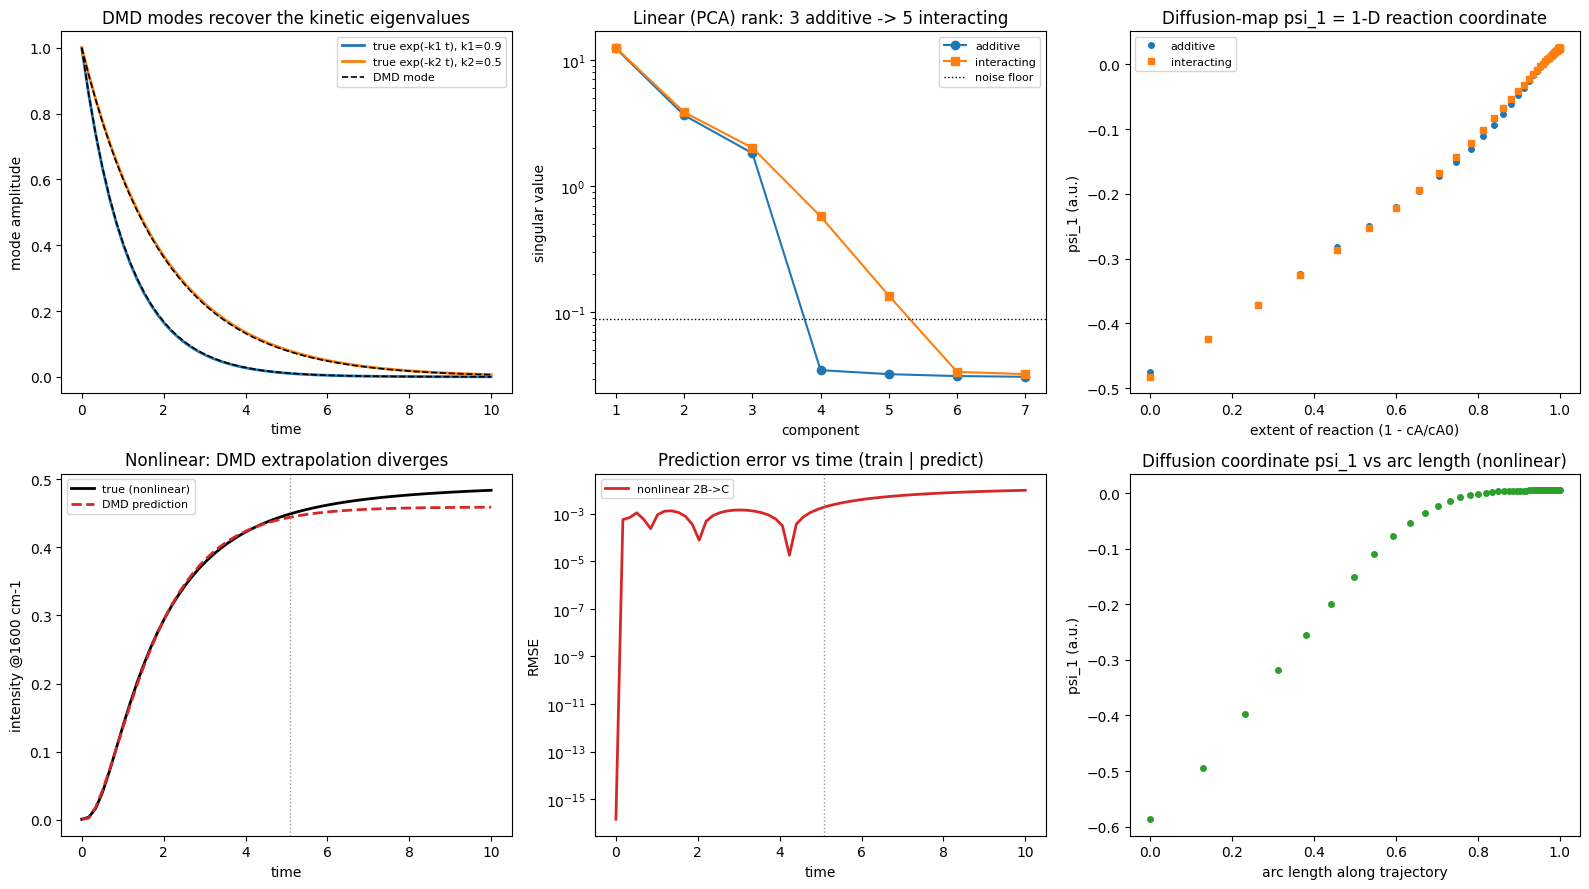

In [7]:
make_figure(t_lin, om_dmd, sv_a, sv_i, thr, extent, psi_a, psi_i,
            lin, non, Dp_non, m, psi_non, arc)

In [8]:
print("\n" + "=" * 72)
print(f"Total runtime: {time.time() - t0:.1f} s")
print("=" * 72)
results


Total runtime: 3.7 s


{'dmd_rates': array([0.50604723, 0.89213156]),
 'rank_add': 3,
 'rank_int': 5,
 'corr_add': np.float64(0.993567050370885),
 'corr_int': np.float64(0.9955402740779158),
 'train_lin': 7.746301723588386e-07,
 'pred_lin': 6.542721297857842e-07,
 'train_non': 0.0009325554063773485,
 'pred_non': 0.0067440374929351975,
 'ratio': 10307.694896225014,
 'rates_non': array([1.96509475e-15, 7.99885503e-01, 1.77569265e+00]),
 'corr_arc': np.float64(0.9305541261864346)}